# Quaternions and Matrix Classification

This notebook accepts coefficients directly as SymPy real expressions: `sp.pi` remains π,
`sp.E` remains e, `sp.sqrt(2)` retains the radical, and `sp.Rational(1, 3)` remains a fraction.


- The four arguments are the real part and the coefficients of i, j, and k, respectively: `Quaternion(w, x, y, z)`.
- For example, π + √2 i − √3 j + k/2: `Quaternion(sp.pi, sp.sqrt(2), -sp.sqrt(3), sp.Rational(1, 2))`.
- π/3: `Quaternion(sp.pi / 3)`; e: `Quaternion(sp.E)`; the cube root of 2: `Quaternion(sp.root(2, 3))`.
- Finite real expressions are also supported, for example `Quaternion(sp.log(2), sp.sin(sp.pi / 7), 0, 0)`.
- Strings and values that have already been converted to floating-point numbers are not accepted.
  For fractions, use `sp.Rational(1, 3)` instead of `1/3` or a decimal such as `0.1`.





In [1]:
from dataclasses import dataclass
from numbers import Integral

import sympy as sp
from IPython.display import display

sqrt = sp.sqrt
Rational = sp.Rational
sp.init_printing()


def exact_real(value):
    """Convert to an exact real expression without guessing radicals or fractions from existing floats."""
    if isinstance(value, (str, bool, float, complex, sp.Float)):
        raise TypeError("Use integers or sp.pi, sp.E, sp.sqrt(...), or sp.Rational(p,q) directly; do not pass strings or floating-point values.")
    value = sp.sympify(value)
    if not isinstance(value, sp.Expr) or value.has(sp.Float):
        raise TypeError("Quaternion coefficients must be exact real expressions without Float values.")
    if value.is_real is not True or value.is_finite is not True:
        raise ValueError("Quaternion coefficients must be finite and real; declare symbolic variables with real=True.")
    return sp.simplify(value)


def exact_zero(value):
    """Test for exact zero; raise an error if undecidable instead of assuming a nonzero value."""
    value = exact_real(value)
    if value == 0 or value.is_zero is True:
        return True
    if value.is_zero is False:
        return False
    raise ValueError(f"Cannot determine exactly whether {value} is zero; assign definite values to symbolic variables.")


def exact_sign(value):
    """Return exactly -1, 0, or 1 without numerical approximation."""
    value = exact_real(value)
    if value == 0 or value.is_zero is True:
        return 0
    if value.is_positive is True:
        return 1
    if value.is_negative is True:
        return -1
    raise ValueError(f"Cannot determine the sign of {value} exactly; assign definite values to symbolic variables.")


def _integer(value, nonnegative=False):
    if isinstance(value, bool) or not isinstance(value, (Integral, sp.Integer)):
        raise ValueError("The exponent must be an integer.")
    value = int(value)
    if nonnegative and value < 0:
        raise ValueError("n must be a nonnegative integer.")
    return value


## Quaternion Class

Use `Quaternion(w, x, y, z)` to enter four real coefficients directly; omitted components default to zero.
The class provides conjugation, inversion, the norm, the squared norm, the real part, integer powers, and addition, subtraction, and multiplication between real numbers and quaternions.
Use `q.inverse()` to compute the inverse; multiplication keeps the left-to-right order explicit.



In [2]:
@dataclass(frozen=True, eq=False)
class Quaternion:
    w: object = 0
    x: object = 0
    y: object = 0
    z: object = 0

    def __post_init__(self):
        for name in ("w", "x", "y", "z"):
            object.__setattr__(self, name, exact_real(getattr(self, name)))

    @staticmethod
    def _coerce(value):
        return value if isinstance(value, Quaternion) else Quaternion(value)

    def components(self):
        return (self.w, self.x, self.y, self.z)

    def __add__(self, other):
        other = self._coerce(other)
        return Quaternion(*(a + b for a, b in zip(self.components(), other.components())))

    def __radd__(self, other):
        return self + other

    def __neg__(self):
        return Quaternion(*(-value for value in self.components()))

    def __sub__(self, other):
        return self + (-self._coerce(other))

    def __rsub__(self, other):
        return self._coerce(other) - self

    def __mul__(self, other):
        other = self._coerce(other)
        a, b, c, d = self.components()
        e, f, g, h = other.components()
        return Quaternion(
            a * e - b * f - c * g - d * h,
            a * f + b * e + c * h - d * g,
            a * g - b * h + c * e + d * f,
            a * h + b * g - c * f + d * e,
        )

    def __rmul__(self, other):
        return self._coerce(other) * self



    def __pow__(self, exponent):
        exponent = _integer(exponent)
        base = self
        if exponent < 0:
            base, exponent = self.inverse(), -exponent
        result = Quaternion(1)
        while exponent:
            if exponent % 2:
                result = result * base
            exponent //= 2
            if exponent:
                base = base * base
        return result

    def __eq__(self, other):
        try:
            other = self._coerce(other)
        except (TypeError, ValueError):
            return NotImplemented
        return (self - other).is_zero()

    def is_zero(self):
        # For real coefficients, all components are zero exactly when the squared norm is zero; no square root is needed.
        return exact_zero(self.norm_squared())

    def conjugate(self):
        return Quaternion(self.w, -self.x, -self.y, -self.z)

    def norm_squared(self):
        return sp.simplify(sum((value ** 2 for value in self.components()), sp.S.Zero))

    def norm(self):
        return sp.simplify(sp.sqrt(self.norm_squared()))

    def inverse(self):
        squared = self.norm_squared()
        if exact_zero(squared):
            raise ZeroDivisionError("The zero quaternion has no inverse.")
        conjugate = self.conjugate()
        return Quaternion(*(value / squared for value in conjugate.components()))

    def real(self):
        return self.w

    def _display_expression(self):
        # These symbols are for display only; actual multiplication uses the Hamilton product defined above.
        i, j, k = sp.symbols("i j k", commutative=False)
        return self.w + self.x * i + self.y * j + self.z * k

    def __str__(self):
        return sp.sstr(self._display_expression())

    def __repr__(self):
        return str(self)

    def _repr_latex_(self):
        return "$" + sp.latex(self._display_expression()) + "$"


def is_zero_quaternion(q):
    return Quaternion._coerce(q).is_zero()


def scale(a, q):
    return exact_real(a) * q


q1: 


pi + sqrt(2)*i + j/3 - k

q2: 


1 - i

Addition: 


...

Conjugate: 


pi - sqrt(2)*i - j/3 + k

Inverse: 


9*pi/(28 + 9*pi**2) - 9*sqrt(2)*i/(28 + 9*pi**2) - 3*j/(28 + 9*pi**2) + 9*k/(28 + 9*pi**2)

Squared norm: 


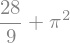

Norm: 


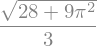

Real part: 


In [3]:
# Direct input example with pi, radicals, and fractions; display renders the symbolic expressions.
q1 = Quaternion(sp.pi, sp.sqrt(2), sp.Rational(1, 3), -1)
q2 = Quaternion(1, -1, 0, 0)
for name, value in [
    ("q1", q1), ("q2", q2),
    ("Addition", q1 + q2), ("Subtraction", q1 - q2),
    ("Multiplication", q1 * q2),
    ("Conjugate", q1.conjugate()), ("Inverse", q1.inverse()),
    ("Squared norm", q1.norm_squared()), ("Norm", q1.norm()),
    ("Real part", q1.real()),
]:
    print(name + ": ")
    display(value)


## Matrix Operations and U(1,1;H) Membership

Check the following five conditions and return True only if all of them hold exactly:

$$|a|=|d|,\quad |b|=|c|,\quad |a|^2-|c|^2=1,\quad
\bar a b=\bar c d,\quad a\bar c=b\bar d.$$




In [4]:
def matrix2(T):
    if len(T) != 2 or any(len(row) != 2 for row in T):
        raise ValueError("T must be a 2-by-2 matrix.")
    return [[Quaternion._coerce(value) for value in row] for row in T]


def identity2():
    return [[Quaternion(1), Quaternion(0)], [Quaternion(0), Quaternion(1)]]


def matmul2(A, B):
    A, B = matrix2(A), matrix2(B)
    return [
        [A[i][0] * B[0][j] + A[i][1] * B[1][j] for j in range(2)]
        for i in range(2)
    ]


def matrix_power2(T, n):
    """Compute T to the power n: start with the identity and multiply by T a total of n times."""
    n = _integer(n, nonnegative=True)
    T = matrix2(T)


    result = identity2()


    for _ in range(n):
        result = matmul2(result, T)

    return result


def Tr(T):
    """Real-valued trace of T=[[a,b],[c,d]]: Tr(T)=2*(a0+d0), where a0 and d0 are the real parts."""
    T = matrix2(T)
    a0 = T[0][0].real()  # Real part of a
    d0 = T[1][1].real()  # Real part of d
    return exact_real(2 * (a0 + d0))


def reduced_trace(T):
    """Keep the original function name as an alias for Tr(T)."""
    return Tr(T)


def compute_delta(T):
    T = matrix2(T)
    a, b = T[0]
    c, d = T[1]
    return sp.simplify((b - c.conjugate()).norm_squared() - (a.real() - d.real()) ** 2)


def u11_conditions(T):
    T = matrix2(T)
    a, b = T[0]
    c, d = T[1]
    aa, bb, cc, dd = [q.norm_squared() for q in (a, b, c, d)]
    return {
        "|a| = |d|": exact_zero(aa - dd),
        "|b| = |c|": exact_zero(bb - cc),
        "|a|² - |c|² = 1": exact_zero(aa - cc - 1),
        "conjugate(a)*b = conjugate(c)*d": (a.conjugate() * b - c.conjugate() * d).is_zero(),
        "a*conjugate(c) = b*conjugate(d)": (a * c.conjugate() - b * d.conjugate()).is_zero(),
    }


def is_in_u11(T):
    return all(u11_conditions(T).values())


def matrix_invariants(T):
    T = matrix2(T)
    if not is_in_u11(T):
        raise ValueError("T is not in U(1,1;H); the recurrences and classification criteria in this notebook do not apply.")
    tau = Tr(T)  # tau = 2*(a0+d0) is real-valued, not a quaternion
    delta = compute_delta(T)
    sigma = Tr(matmul2(T, T))  # Tr(T^2) using the same trace definition
    beta = sp.simplify(sp.Rational(1, 4) * tau ** 2 + delta + 2)
    if not exact_zero(beta - (tau ** 2 - sigma) / 2):
        raise ValueError("The matrix value of beta is inconsistent with the reduced-trace identity.")
    return {"tau": tau, "delta": delta, "beta": beta, "sigma": sigma}


## Exact Classification

For $T=\begin{pmatrix}a&b\\c&d\end{pmatrix}$, let $a_0=\operatorname{Re}(a)$ and $d_0=\operatorname{Re}(d)$. Throughout, use

$$\tau=\operatorname{Tr}(T)=2(a_0+d_0)\in\mathbb{R}.$$

`reduced_trace(T)` is compatible with `Tr(T)`.


$$\sigma=\operatorname{Tr}(T^2),\qquad \beta=\frac{\tau^2}{4}+\delta+2=\frac{\tau^2-\sigma}{2}.$$

Since $\operatorname{Tr}(I)=4$, the trace sequence continues to use $s_0=4,s_1=\tau,s_2=\sigma$, and the final classification step still compares $s_n^2$ with $16$.

`compute_qn(T,n)` returns the real number $q_n$; `compute_deltan(T,n)` returns $q_n^2\delta$.
The initial values are $q_0=0,q_1=1,q_2=\tau,q_3=3\tau^2/4-\delta-3$.

`compute_un_sn` consistently uses $u_n=b_n-\overline{c_n}$ (only $c_n$ is conjugated); $s_n=\operatorname{Tr}(T^n)=2(\operatorname{Re}(a_n)+\operatorname{Re}(d_n))$, and when $\delta_n=0$, $\operatorname{Re}(a_n)=\operatorname{Re}(d_n)$.
`classify_Tn(T,n)` computes $\delta_n$ automatically; an already computed exact `delta_n` can also be passed explicitly.
When $\delta_n=0$, if the updated $u_n=b_n-\overline{c_n}\ne0$, the classification is compound parabolic (`compound parabolic`). If $u_n=0$, continue by checking $b_n$, then compare $s_n^2$ with $16$.

Since $\tau,\beta$ are both real, the conjugate of $c_k$ satisfies the same linear recurrence; therefore, the recurrence coefficients for $u_k$ remain unchanged, and only the new initial values of the conjugate difference are needed.



In [7]:
def compute_qn(T, n):
    n = _integer(n, nonnegative=True)
    values = matrix_invariants(T)
    tau, delta, beta = values["tau"], values["delta"], values["beta"]
    q = [sp.S.Zero, sp.S.One, tau, sp.simplify(sp.Rational(3, 4) * tau ** 2 - delta - 3)]
    for k in range(4, n + 1):
        q.append(sp.simplify(tau * q[k - 1] - beta * q[k - 2] + tau * q[k - 3] - q[k - 4]))
    return q[n]


def compute_deltan(T, n):
    q_n = compute_qn(T, n)
    return sp.simplify(q_n ** 2 * compute_delta(T))


def compute_un_sn(T, n):
    """Compute u_n=b_n-conjugate(c_n) and the real-valued trace s_n=Tr(T^n) exactly."""
    n = _integer(n, nonnegative=True)
    T = matrix2(T)
    values = matrix_invariants(T)
    tau, beta, sigma = values["tau"], values["beta"], values["sigma"]
    T2 = matmul2(T, T)
    T3 = matmul2(T2, T)
    # For T^k=[[a_k,b_k],[c_k,d_k]], every initial value uses b_k-conjugate(c_k).
    u = [
        Quaternion(0),                           # u_0=0 because T^0=I
        T[0][1] - T[1][0].conjugate(),            # u_1=b_1-conjugate(c_1)
        T2[0][1] - T2[1][0].conjugate(),          # u_2=b_2-conjugate(c_2)
        T3[0][1] - T3[1][0].conjugate(),          # u_3=b_3-conjugate(c_3)
    ]
    s = [sp.Integer(4), tau, sigma, sp.simplify(tau * sigma - beta * tau + 3 * tau)]
    for k in range(4, n + 1):
        u.append(tau * u[k - 1] - beta * u[k - 2] + tau * u[k - 3] - u[k - 4])
        s.append(sp.simplify(tau * s[k - 1] - beta * s[k - 2] + tau * s[k - 3] - s[k - 4]))
    return u[n], s[n]


def classify_Tn(T, n, delta_n=None):
    n = _integer(n, nonnegative=True)
    T = matrix2(T)
    matrix_invariants(T)
    if delta_n is None:
        delta_n = compute_deltan(T, n)
    sign = exact_sign(delta_n)
    if sign < 0:
        return "compound elliptic"
    if sign > 0:
        return "compound loxodromic"
    # Here delta_n=0; use the conjugate difference u_n to test for the compound parabolic case.
    u_n, s_n = compute_un_sn(T, n)
    if not u_n.is_zero():
        return "compound parabolic"
    b_n = matrix_power2(T, n)[0][1]
    if b_n.is_zero():
        return "simple elliptic"
    sign = exact_sign(s_n ** 2 - 16)
    if sign < 0:
        return "simple elliptic"
    if sign == 0:
        return "simple parabolic"
    return "simple loxodromic"


## Enter the Matrix and Exponent Here

Edit `a, b, c, d, n` below. Enter coefficients directly as expressions such as `sp.pi`, `sp.E`, `sp.sqrt(...)`, and `sp.Rational(p,q)`.
The example $T=\begin{pmatrix}\sqrt{1+\pi^2}&\pi\\\pi&\sqrt{1+\pi^2}\end{pmatrix}$ belongs to $U(1,1;\mathbb H)$.
Its square is $\begin{pmatrix}1+2\pi^2&2\pi\sqrt{1+\pi^2}\\2\pi\sqrt{1+\pi^2}&1+2\pi^2\end{pmatrix}$.



In [8]:
a = Quaternion(sp.sqrt(1 + sp.pi ** 2))
b = Quaternion(sp.pi)
c = Quaternion(sp.pi)
d = Quaternion(sp.sqrt(1 + sp.pi ** 2))
n = 2
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")


Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(1 + pi**2) ; d0 = sqrt(1 + pi**2)
tau = Tr(T) = 2*(a0+d0) = 4*sqrt(1 + pi**2)
Parameters: {'tau': 4*sqrt(1 + pi**2), 'delta': 0, 'beta': 6 + 4*pi**2, 'sigma': 4 + 8*pi**2}
q_2 = 4*sqrt(1 + pi**2)
delta_2 = 0
u_2 = b_2 - conjugate(c_2) = 0
s_2 = 4 + 8*pi**2
T^2: 
[1 + 2*pi**2, 2*pi*sqrt(1 + pi**2)]
[2*pi*sqrt(1 + pi**2), 1 + 2*pi**2]
Classification: simple loxodromic


In [58]:
r = sp.sqrt(2) / 2
a = Quaternion(0,r,r,0)
b = Quaternion(0)
c = Quaternion(0)
d = Quaternion(r,0,0,-r)
n = 1
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")


Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 0 ; d0 = sqrt(2)/2
tau = Tr(T) = 2*(a0+d0) = sqrt(2)
Parameters: {'tau': sqrt(2), 'delta': -1/2, 'beta': 2, 'sigma': -2}
q_1 = 1
delta_1 = -1/2
u_1 = b_1 - conjugate(c_1) = 0
s_1 = sqrt(2)
T^1: 
[sqrt(2)*i/2 + sqrt(2)*j/2, 0]
[0, sqrt(2)/2 - sqrt(2)*k/2]
Classification: compound elliptic


In [15]:
r1 = sp.sqrt(3) / 3
a = Quaternion(r1,r1,r1,0)
b = Quaternion(0)
c = Quaternion(0)
d = Quaternion(r1,0,-r1,-r1)
n = 10
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(3)/3 ; d0 = sqrt(3)/3
tau = Tr(T) = 2*(a0+d0) = 4*sqrt(3)/3
Parameters: {'tau': 4*sqrt(3)/3, 'delta': 0, 'beta': 10/3, 'sigma': -4/3}
q_10 = -220*sqrt(3)/243
delta_10 = 0
u_10 = b_10 - conjugate(c_10) = 0
s_10 = -964/243
T^10: 
[-241/243 - 22*i/243 - 22*j/243, 0]
[0, -241/243 + 22*j/243 + 22*k/243]
Classification: simple elliptic


In [18]:

a = Quaternion(1,0,1,0)
b = Quaternion(1)
c = Quaternion(1)
d = Quaternion(1,0,-1,0)
n = 5
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 1 ; d0 = 1
tau = Tr(T) = 2*(a0+d0) = 4
Parameters: {'tau': 4, 'delta': 0, 'beta': 6, 'sigma': 4}
q_5 = 25
delta_5 = 0
u_5 = b_5 - conjugate(c_5) = 0
s_5 = 4
T^5: 
[1 + 5*j, 5]
[5, 1 - 5*j]
Classification: simple parabolic


In [21]:
r = sp.sqrt(2) 
a = Quaternion(0,r,0,0)
b = Quaternion(1)
c = Quaternion(1)
d = Quaternion(0,-r,0,0)
n = 10
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 0 ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': 0, 'beta': 2, 'sigma': -4}
q_10 = 0
delta_10 = 0
u_10 = b_10 - conjugate(c_10) = 0
s_10 = -4
T^10: 
[-1, 0]
[0, -1]
Classification: simple elliptic


In [52]:
#n=1 compound elliptic
#n=2 simple elliptic
r = sp.sqrt(2) / 2
a = Quaternion(r, r)
b = Quaternion(0)
c = Quaternion(0)
d = Quaternion(-r, r)
n = 2
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(2)/2 ; d0 = -sqrt(2)/2
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': -2, 'beta': 0, 'sigma': 0}
q_2 = 0
delta_2 = 0
u_2 = b_2 - conjugate(c_2) = 0
s_2 = 0
T^2: 
[i, 0]
[0, -i]
Classification: simple elliptic


In [23]:
r = sp.sqrt(2) 
a = Quaternion(r,1,0,0)
b = Quaternion(r)
c = Quaternion(r)
d = Quaternion(r,-1,0,0)
n = 10
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(2) ; d0 = sqrt(2)
tau = Tr(T) = 2*(a0+d0) = 4*sqrt(2)
Parameters: {'tau': 4*sqrt(2), 'delta': 0, 'beta': 10, 'sigma': 12}
q_10 = 23780*sqrt(2)
delta_10 = 0
u_10 = b_10 - conjugate(c_10) = 0
s_10 = 13452
T^10: 
[3363 + 2378*sqrt(2)*i, 4756]
[4756, 3363 - 2378*sqrt(2)*i]
Classification: simple loxodromic


In [30]:
#n=1 compound parabolic
#n>=2 simple parabolic
a = Quaternion(1,0,0,1)
b = Quaternion(1)
c = Quaternion(-1)
d = Quaternion(-1,0,0,1)
n = 2
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 1 ; d0 = -1
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': 0, 'beta': 2, 'sigma': -4}
q_2 = 0
delta_2 = 0
u_2 = b_2 - conjugate(c_2) = 0
s_2 = -4
T^2: 
[-1 + 2*k, 2*k]
[-2*k, -1 - 2*k]
Classification: simple parabolic


In [39]:
a = Quaternion(1,0,1,0)
b = Quaternion(1)
c = Quaternion(0,1,0,0)
d = Quaternion(0,1,0,-1)
n = 10
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 1 ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 2
Parameters: {'tau': 2, 'delta': 1, 'beta': 4, 'sigma': -4}
q_10 = -198
delta_10 = 39204
u_10 = b_10 - conjugate(c_10) = -198 - 198*i
s_10 = 76
T^10: 
[-80 - 39*i - 126*j, -123 - 75*i - 39*j + 39*k]
[75 - 123*i + 39*j - 39*k, 118 - 87*i + 48*k]
Classification: compound loxodromic


In [41]:
r2= sp.sqrt(3) 
a = Quaternion(r2,0,0,0)
b = Quaternion(1,1,0,0)
c = Quaternion(1,1,0,0)
d = Quaternion(0,r2,0,0)
n = 1000
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(3) ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 2*sqrt(3)
Parameters: {'tau': 2*sqrt(3), 'delta': 1, 'beta': 6, 'sigma': 0}
q_1000 = 0
delta_1000 = 0
u_1000 = b_1000 - conjugate(c_1000) = 0
s_1000 = 18827981475636667501720319084170182259157698276812537914272300032825934702914950136816485406770105309488030364246706194567410444479940474190352020584887376606853384240040178013198374457267407008599599871524984537235646470875889525873396864836083432827777250430434486631496838663694863748
T^1000: 
[4706995368909166875430079771042545564789424569203134478568075008206483675728737534204121351692526327372007591061676548641852611119985118547588005146221844151713346060010044503299593614316851752149899967881246134308911617718972381468349216209020858206944312607608621657874209665923715937 - 81527551299420879823976088413047723860154381

In [42]:
r2= sp.sqrt(3) 
a = Quaternion(r2,0,0,0)
b = Quaternion(1,1,0,0)
c = Quaternion(1,1,0,0)
d = Quaternion(0,r2,0,0)
n = 10
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(3) ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 2*sqrt(3)
Parameters: {'tau': 2*sqrt(3), 'delta': 1, 'beta': 6, 'sigma': 0}
q_10 = 418*sqrt(3)
delta_10 = 524172
u_10 = b_10 - conjugate(c_10) = 836*sqrt(3)*i
s_10 = 0
T^10: 
[627 + 362*i, 418*sqrt(3)*i]
[418*sqrt(3)*i, -627 + 362*i]
Classification: compound loxodromic


In [49]:
#n=19 compound loxodromic
#n=20 simple loxodromic
r2= sp.sqrt(3) 
a = Quaternion(r2,0,0,0)
b = Quaternion(1,1,0,0)
c = Quaternion(1,1,0,0)
d = Quaternion(0,r2,0,0)
n = 19
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(3) ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 2*sqrt(3)
Parameters: {'tau': 2*sqrt(3), 'delta': 1, 'beta': 6, 'sigma': 0}
q_19 = 191861
delta_19 = 36810643321
u_19 = b_19 - conjugate(c_19) = 383722*i
s_19 = -221542*sqrt(3)
T^19: 
[40545*sqrt(3) + 151316*sqrt(3)*i, -191861 + 191861*i]
[-191861 + 191861*i, -151316*sqrt(3) - 40545*sqrt(3)*i]
Classification: compound loxodromic


In [53]:
#n=19 compound loxodromic
#n=20 simple loxodromic
r2= sp.sqrt(3) 
a = Quaternion(r2,0,0,0)
b = Quaternion(1,1,0,0)
c = Quaternion(1,1,0,0)
d = Quaternion(0,r2,0,0)
n = 20
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(3) ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 2*sqrt(3)
Parameters: {'tau': 2*sqrt(3), 'delta': 1, 'beta': 6, 'sigma': 0}
q_20 = 0
delta_20 = 0
u_20 = b_20 - conjugate(c_20) = 0
s_20 = -1048348
T^20: 
[-262087 + 453948*i, -302632*sqrt(3)]
[-302632*sqrt(3), -262087 - 453948*i]
Classification: simple loxodromic


In [55]:

#n=1 compound loxodromic
#n=2 simple loxodromic
r2= sp.sqrt(3) 
a = Quaternion(0, sp.sqrt(2))
b = Quaternion(0, 1)
c = Quaternion(0, 1)
d = Quaternion(0, sp.sqrt(2))
n = 2
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 0 ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': 4, 'beta': 6, 'sigma': -12}
q_2 = 0
delta_2 = 0
u_2 = b_2 - conjugate(c_2) = 0
s_2 = -12
T^2: 
[-3, -2*sqrt(2)]
[-2*sqrt(2), -3]
Classification: simple loxodromic


In [68]:
a = Quaternion(-1,1,0,0)
b = Quaternion(0,1,0,0)
c = Quaternion(0,1,0,0)
d = Quaternion(1,1,0,0)
n = 1
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = -1 ; d0 = 1
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': 0, 'beta': 2, 'sigma': -4}
q_1 = 1
delta_1 = 0
u_1 = b_1 - conjugate(c_1) = 2*i
s_1 = 0
T^1: 
[-1 + i, i]
[i, 1 + i]
Classification: compound parabolic


In [67]:

a = Quaternion(0,sp.Rational(5, 4),0,0)
b = Quaternion(0,sp.Rational(3, 4),0,0)
c = Quaternion(0,sp.Rational(3, 4),0,0)
d = Quaternion(0,sp.Rational(5, 4),0,0)
n = 1
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 0 ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': 9/4, 'beta': 17/4, 'sigma': -17/2}
q_1 = 1
delta_1 = 9/4
u_1 = b_1 - conjugate(c_1) = 3*i/2
s_1 = 0
T^1: 
[5*i/4, 3*i/4]
[3*i/4, 5*i/4]
Classification: compound loxodromic


In [70]:
r3= sp.sqrt(2)/2
a = Quaternion(r3, r3)
b = Quaternion(0)
c = Quaternion(0)
d = Quaternion(-r3, -r3)
n = 1
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = sqrt(2)/2 ; d0 = -sqrt(2)/2
tau = Tr(T) = 2*(a0+d0) = 0
Parameters: {'tau': 0, 'delta': -2, 'beta': 0, 'sigma': 0}
q_1 = 1
delta_1 = -2
u_1 = b_1 - conjugate(c_1) = 0
s_1 = 0
T^1: 
[sqrt(2)/2 + sqrt(2)*i/2, 0]
[0, -sqrt(2)/2 - sqrt(2)*i/2]
Classification: compound elliptic


In [74]:
a = Quaternion(1,0,0,0)
b = Quaternion(0)
c = Quaternion(0)
d = Quaternion(0,1,0,0)
n = 3
T = [[a, b], [c, d]]

print("Five conditions for U(1,1;H):")
for name, result in u11_conditions(T).items():
    print(f"  {name}: {result}")

if is_in_u11(T):
    print("a0 =", a.real(), "; d0 =", d.real())
    print("tau = Tr(T) = 2*(a0+d0) =", Tr(T))
    print("Parameters:", matrix_invariants(T))
    print(f"q_{n} =", compute_qn(T, n))
    delta_n = compute_deltan(T, n)
    u_n, s_n = compute_un_sn(T, n)
    print(f"delta_{n} =", delta_n)
    print(f"u_{n} = b_{n} - conjugate(c_{n}) =", u_n)
    print(f"s_{n} =", s_n)
    print(f"T^{n}: ")
    Tn = matrix_power2(T, n)
    for row in Tn:
        print(row)
    print("Classification:", classify_Tn(T, n, delta_n))
else:
    print("The matrix is not in U(1,1;H); classification is skipped.")

Five conditions for U(1,1;H):
  |a| = |d|: True
  |b| = |c|: True
  |a|² - |c|² = 1: True
  conjugate(a)*b = conjugate(c)*d: True
  a*conjugate(c) = b*conjugate(d): True
a0 = 1 ; d0 = 0
tau = Tr(T) = 2*(a0+d0) = 2
Parameters: {'tau': 2, 'delta': -1, 'beta': 2, 'sigma': 0}
q_3 = 1
delta_3 = -1
u_3 = b_3 - conjugate(c_3) = 0
s_3 = 2
T^3: 
[1, 0]
[0, -i]
Classification: compound elliptic
